In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the dataset
file_path = '/Users/clcx/Desktop/Trimester 3/SIT719 Analytics for Security and Privacy/SIT719-5.2C/cybersecurity_attacks-main/cybersecurity_attacks.csv'
data = pd.read_csv(file_path)

In [ ]:
# 1.1 Display the first few rows of the dataset
print(data.head())

             Timestamp Source IP Address Destination IP Address  Source Port  \
0  2023-05-30 06:33:58     103.216.15.12           84.9.164.252        31225   
1  2020-08-26 07:08:30    78.199.217.198         66.191.137.154        17245   
2  2022-11-13 08:23:25      63.79.210.48          198.219.82.17        16811   
3  2023-07-02 10:38:46     163.42.196.10        101.228.192.255        20018   
4  2023-07-16 13:11:07     71.166.185.76        189.243.174.238         6131   

   Destination Port Protocol  Packet Length Packet Type Traffic Type  \
0             17616     ICMP            503        Data         HTTP   
1             48166     ICMP           1174        Data         HTTP   
2             53600      UDP            306     Control         HTTP   
3             32534      UDP            385        Data         HTTP   
4             26646      TCP           1462        Data          DNS   

                                        Payload Data  ... Action Taken  \
0  Qui natus

In [4]:
# 1.2 Handle Missing Values
missing_values_summary = data.isnull().sum()
print("Missing Values Summary:\n", missing_values_summary)

Missing Values Summary:
 Timestamp                     0
Source IP Address             0
Destination IP Address        0
Source Port                   0
Destination Port              0
Protocol                      0
Packet Length                 0
Packet Type                   0
Traffic Type                  0
Payload Data                  0
Malware Indicators        20000
Anomaly Scores                0
Alerts/Warnings           20067
Attack Type                   0
Attack Signature              0
Action Taken                  0
Severity Level                0
User Information              0
Device Information            0
Network Segment               0
Geo-location Data             0
Proxy Information         19851
Firewall Logs             19961
IDS/IPS Alerts            20050
Log Source                    0
dtype: int64


In [5]:
# Fill missing values
data_cleaned = data.copy()
categorical_columns = data_cleaned.select_dtypes(include=['object']).columns
numerical_columns = data_cleaned.select_dtypes(include=['float64', 'int64']).columns

data_cleaned[categorical_columns] = data_cleaned[categorical_columns].fillna('Unknown')
data_cleaned[numerical_columns] = data_cleaned[numerical_columns].fillna(data_cleaned[numerical_columns].mean())

In [6]:
# 1.3 Analyze when most of the attacks happened (by month and attack type)
data_cleaned['Month'] = pd.to_datetime(data_cleaned['Timestamp']).dt.month_name()
attack_monthly_counts = data_cleaned.groupby(['Month', 'Attack Type']).size().unstack(fill_value=0)

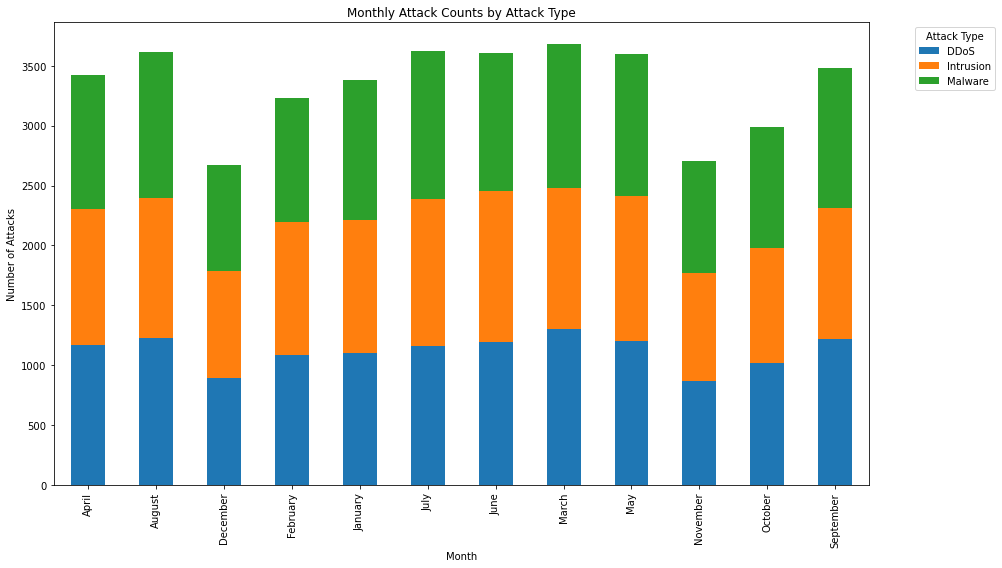

In [7]:
# Plot the monthly attack counts by attack type
attack_monthly_counts.plot(kind='bar', stacked=True, figsize=(14, 8))
plt.title('Monthly Attack Counts by Attack Type')
plt.xlabel('Month')
plt.ylabel('Number of Attacks')
plt.legend(title='Attack Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

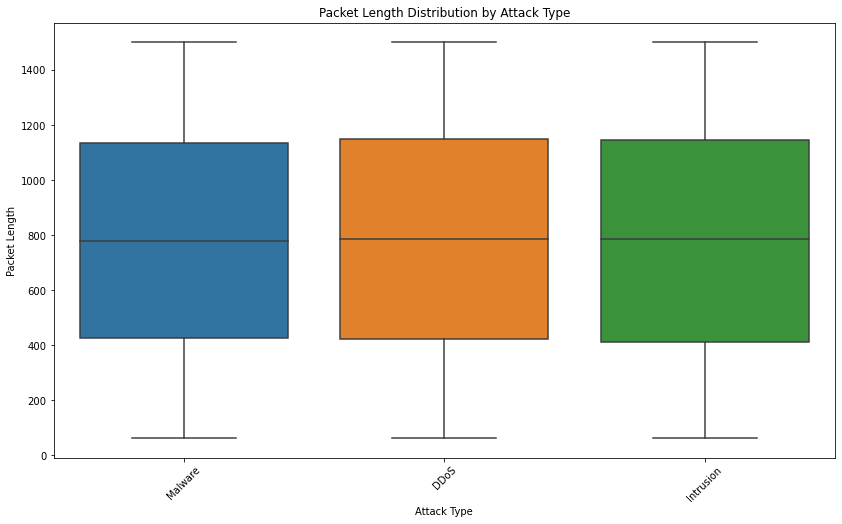

In [8]:
# 1.4 Show the packet length distribution for different attack types
plt.figure(figsize=(14, 8))
sns.boxplot(data=data_cleaned, x='Attack Type', y='Packet Length')
plt.title('Packet Length Distribution by Attack Type')
plt.xticks(rotation=45)
plt.xlabel('Attack Type')
plt.ylabel('Packet Length')
plt.show()

In [20]:
# 2. Provide 5 unique insights

# Insight 1: Top Attack Types
top_attack_types = data_cleaned['Attack Type'].value_counts()
print("Top Attack Types:\n", top_attack_types)

Top Attack Types:
 DDoS         13428
Malware      13307
Intrusion    13265
Name: Attack Type, dtype: int64


In [16]:
# Insight 2: Severity Levels
severity_counts = data_cleaned['Severity Level'].value_counts()
print("Severity Levels:\n", severity_counts)

Severity Levels:
 Medium    13435
High      13382
Low       13183
Name: Severity Level, dtype: int64


In [17]:
# Insight 3: Most Common Protocol
common_protocol = data_cleaned['Protocol'].value_counts().idxmax()
print("Most Common Protocol:", common_protocol)

Most Common Protocol: ICMP


In [18]:
# Insight 4: Average Packet Length by Attack Type
avg_packet_length_by_attack = data_cleaned.groupby('Attack Type')['Packet Length'].mean()
print("Average Packet Length by Attack Type:\n", avg_packet_length_by_attack)

Average Packet Length by Attack Type:
 Attack Type
DDoS         785.348749
Intrusion    780.924387
Malware      778.047945
Name: Packet Length, dtype: float64


In [19]:
# Insight 5: Actions Taken
actions_taken_counts = data_cleaned['Action Taken'].value_counts()
print("Actions Taken Counts:\n", actions_taken_counts)

Actions Taken Counts:
 Blocked    13529
Ignored    13276
Logged     13195
Name: Action Taken, dtype: int64


In [ ]:

# Visualization for Insight 1: Top Attack Types
plt.figure(figsize=(10, 6))
top_attack_types.plot(kind='bar', color='skyblue')
plt.ylim(13000, 14000)  # Adjust the y-axis range
plt.title('Top Attack Types (Zoomed In)')
plt.xlabel('Attack Type')
plt.ylabel('Number of Attacks')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('top_attack_types.png') 
plt.show()

# Visualization for Insight 2: Severity Levels
plt.figure(figsize=(10, 6))
severity_counts.plot(kind='bar', color='salmon')
plt.ylim(13000, 14000)  # Adjust the y-axis range
plt.title('Attack Severity Levels (Zoomed In)')
plt.xlabel('Severity Level')
plt.ylabel('Number of Attacks')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('severity_levels.png') 
plt.show()

# Visualization for Insight 4: Average Packet Length by Attack Type
plt.figure(figsize=(10, 6))
avg_packet_length_by_attack.plot(kind='bar', color='lightgreen')
plt.ylim(700, 800)  # Adjust the y-axis range
plt.title('Average Packet Length by Attack Type')
plt.xlabel('Attack Type')
plt.ylabel('Average Packet Length (bytes)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('packet_length.png') 
plt.show()

# Visualization for Insight 5: Actions Taken
plt.figure(figsize=(10, 6))
actions_taken_counts.plot(kind='bar', color='orange')
plt.ylim(13000, 14000)  # Adjust the y-axis range
plt.title('Actions Taken for Detected Attacks (Zoomed In)')
plt.xlabel('Action Taken')
plt.ylabel('Number of Actions')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('action_taken.png') 
plt.show()